#
**<h1 align="center">LAB Report: Interpolation</h1>**


<div align="right">
  <strong>Name: Ahtasham Haider</strong><br>
  <strong>SC Code: SC26M004</strong>
</div>

---



## **Module Import**

In [89]:
import numpy as np                      # for maths
import matplotlib.pyplot as plt         # For Plots

## **Problem Statement:**

*   Construct a smooth NACA-abcd Airfoil surface using NACA Airfoil Equation
*   Reconstruct the same Airfoil using Lagrange Interpolation.
*   Plot both the Airfoil and Compare the plots.
*   Calculate Max error and RMS Error between actual Airfoil.
*   How to improve Errors?
*   Reconstruct the airfoil using cubic splines and quantify the errors.







## **1: NACA MPTT Airfoil Equation**

The NACA airfoil series is a set of airfoil shapes developed by the National Advisory Committee for Aeronautics (NACA). The shape of a NACA airfoil is described using a series of digits following the word "NACA".

#### Four-Digit Series (NACA MPTT)

For a NACA four-digit airfoil, the digits define the following:

*   **M**: Maximum camber (first digit) as a percentage of the chord (0.01 = 1%)
*   **P**: Position of the maximum camber (second digit) in tenths of the chord (0.05 = 50% of the chord)
*   **TT**: Maximum thickness (third and fourth digits) as a percentage of the chord (0.12 = 12% of the chord)

The **camber line** ($y_c$) is given by:

For $0 \le x \le p \cdot c$:

$y_c = \frac{m}{p^2}(2px - x^2)$

For $p \cdot c < x \le c$:

$y_c = \frac{m}{(1-p)^2}((1-2p)c + 2px - x^2)$

Where:
*   $x$ is the position along the chord
*   $c$ is the chord length (typically normalized to 1)
*   $m$ is the maximum camber as a fraction of the chord
*   $p$ is the position of the maximum camber as a fraction of the chord

The **half-thickness distribution** ($y_t$) is given by:

$y_t = \frac{t}{0.2} (0.2969\sqrt{x} - 0.1260x - 0.3516x^2 + 0.2843x^3 - 0.1036x^4)$

Where:
*   $t$ is the maximum thickness as a fraction of the chord

The **angle of the camber line** ($\theta$) is given by:

$ \frac{dy_c}{dx} = \begin{cases} \frac{2m}{p^2}(p-x) & 0 \le x \le pc \\ \frac{2m}{(1-p)^2}(p-x) & pc < x \le c \end{cases} $

$ \theta = \arctan\left(\frac{dy_c}{dx}\right) $

Finally, the **coordinates of the upper surface** $(x_u, y_u)$ and **lower surface** $(x_l, y_l)$ are:

$x_u = x - y_t \sin(\theta)$

$y_u = y_c + y_t \cos(\theta)$

$x_l = x + y_t \sin(\theta)$

$y_l = y_c - y_t \cos(\theta)$




> [**REF**](https://en.wikipedia.org/wiki/NACA_airfoil)




In [90]:
class Airfoil():
    def __init__(self, m, p, t):
        self.m = m
        self.p = p
        self.t = t
        self.name = f"NACA {int(100*m)}{int(10*p)}{int(100*t)}"

    def camber(self, x):
        m = self.m
        p = self.p
        y_c = np.where(x <= p,
                    m/p**2*(2*p*x - x**2),
                    m/(1 - p)**2*((1-2*p) + 2*p*x - x**2))
        return y_c

    def half_thickness(self, x):
        y_t = 5*self.t*(0.2969*np.sqrt(x) - 0.126*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)
        return y_t

    def theta(self, x):
        m = self.m
        p = self.p
        dy_dx = np.where(x <= p, 2*m/p**2*(p-x), 2*m/(1-p)**2*(p-x))
        return np.arctan(dy_dx)

    def generate_airfoil(self, x):
        y_t = self.half_thickness(x)
        y_c = self.camber(x)
        theta = self.theta(x)

        x_u = x - y_t*np.sin(theta)
        y_u = y_c + y_t*np.cos(theta)

        x_l = x + y_t*np.sin(theta)
        y_l = y_c - y_t*np.cos(theta)

        return y_c, x_u, y_u, x_l, y_l

In [91]:
np.random.seed(2)
m = np.random.randint(2, 5)/100
p = np.random.randint(3, 6)/10
t = np.random.randint(10, 26)/100

airfoil = Airfoil(m, p, t)

In [92]:
eval_inp = np.linspace(0, 1, 500)
y_c, x_u, y_u, x_l, y_l = airfoil.generate_airfoil(eval_inp)

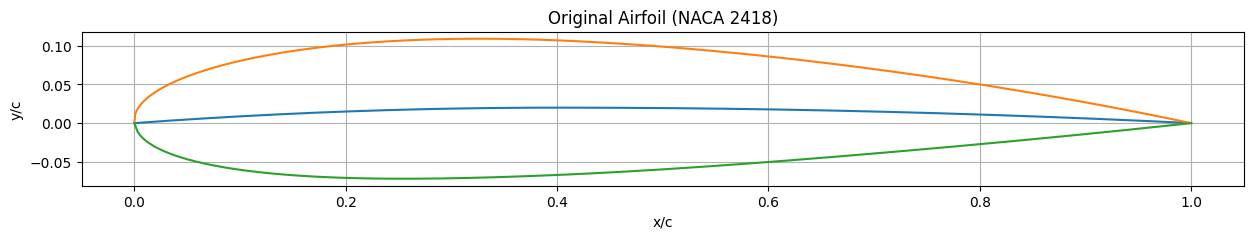

In [93]:
plt.figure(figsize=(15, 2))
plt.plot(eval_inp, y_c)
plt.plot(x_u, y_u)
plt.plot(x_l, y_l)
plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"Original Airfoil ({airfoil.name})")
plt.show()

## **2: Lagrange Interpolation**

Lagrange interpolation is a method for interpolating a polynomial that passes through a given set of data points. For a given set of $n+1$ data points $(x_0, y_0), (x_1, y_1), ..., (x_n, y_n)$, where no two $x_i$ are the same, the Lagrange interpolation polynomial $L(x)$ of degree at most $n$ is given by:

$L(x) = \sum_{j=0}^{n} y_j L_j(x)$

Where $L_j(x)$ are the Lagrange basis polynomials, defined as:

$L_j(x) = \prod_{k=0, k \neq j}^{n} \frac{x - x_k}{x_j - x_k}$

This polynomial has the property that $L_j(x_j) = 1$ and $L_j(x_k) = 0$ for $k \neq j$, ensuring that $L(x_i) = y_i$ for all given data points.


> [**REF**](https://www.google.com/search?q=lagrange+Interpolation&sourceid=chrome&ie=UTF-8&amc=1&gs_lcrp=EgZjaHJvbWUyBggAEEUYOTINCAEQABiABBjwBRieBjINCAIQABiABBjwBRieBjIQCAMQABiABBjwBRieBhi0BzINCAQQABiABBjwBRieBjINCAUQABiABBjwBRieBtIBCTgxMDFqMGozMagCA7ACAeoHCggBEAAYACAAKAA&oq=lagrange+Interpolation&udm=50&aep=42&cud=0&source=chrome.crn.rb&mstk=AUtExfCQY6gq0gNIG55fhaFH1UYMKiljdm3Fzz3kJjISkItd0zvOted2M9vCMt9Dr8iA3vvGxlF21L_JkLOEhn_fRAoEKyQPginPaNo6GIwNWINzfLGWDFJtKgePEgDLq9qgssPaIZjf_4NJLKxTKf-inhNPTOa3EIGTBIuVdiWGUrwKojJKdI1s6IvXzltomRAxOfKAv5lEFW74vtc9iI7u6ah_Kcj9rlUTgxIBZ3oUDo1hdNIEPGxyxs_9bA&csuir=1&atvm=2)



In [94]:
def Lagrange(x, y, xx):
    n = len(x)
    result = np.zeros_like(xx, dtype=float)
    for i in range(n):
        pd = 1
        for j in range(len(x)):
            if j!=i:
                pd *= (xx - x[j])/(x[i] - x[j])
        result += y[i]*pd
    return result

In [95]:
train_inp = np.linspace(0, 1, 15)
_ , x_u_train, y_u_train, x_l_train, y_l_train = airfoil.generate_airfoil(train_inp)

In [96]:
y_u_interp = Lagrange(x_u_train, y_u_train, x_u)
y_l_interp = Lagrange(x_l_train, y_l_train, x_l)

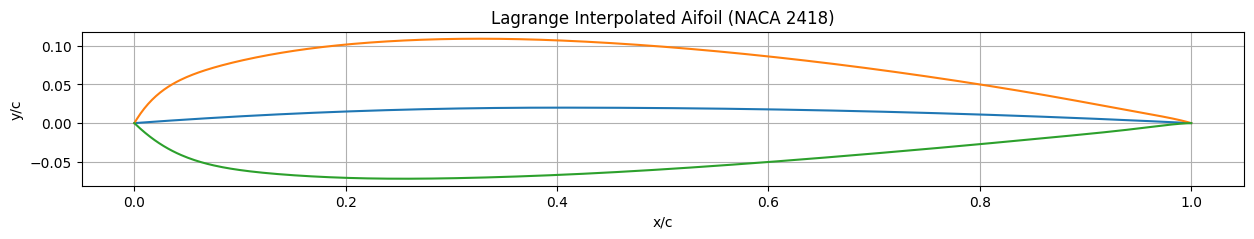

In [97]:
plt.figure(figsize=(15, 2))
plt.plot(eval_inp, y_c)
plt.plot(x_u, y_u_interp)
plt.plot(x_l, y_l_interp)
plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"Lagrange Interpolated Aifoil ({airfoil.name})")
plt.show()

## **3: Comparing the both the Plots**
        
> Poor approximation near leading edge is due to the fact that that leading edge has more curvature and it requires more sample points near leading edge to correctly capture the curvature.





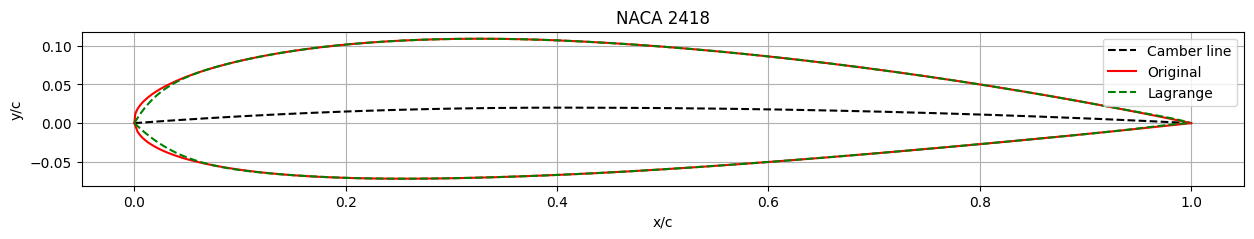

In [98]:
plt.figure(figsize=(15, 2))

plt.plot(eval_inp, y_c, "k--", label="Camber line")

plt.plot(x_u, y_u, "r", label="Original")
plt.plot(x_u, y_u_interp, "g--", label="Lagrange")

plt.plot(x_l, y_l, "r")
plt.plot(x_l, y_l_interp, "g--")

plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(airfoil.name)
plt.legend()
plt.show()

## **4: Error Determination**

##### **1: MAX Error**

$$\text{Max Error} = \max_{i=1}^{n} |y_i - \hat{y}_i|$$


In [99]:
# calculate MAX error
err_u = np.max(np.abs(y_u - y_u_interp))
err_l = np.max(np.abs(y_l - y_l_interp))
print(f"MAX error in upper surface: {err_u}")
print(f"MAX error in lower surface: {err_l}")

MAX error in upper surface: 0.011671765238304788
MAX error in lower surface: 0.009490342360128995


#####**2: RMS Error**

$$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$


In [100]:
# calculate RMS error
adj = np.concatenate((y_u - y_u_interp, y_l - y_l_interp))
rms_error = np.sqrt(np.mean(adj**2))
print(f"RMS error: {rms_error}")

RMS error: 0.0014950611857033173


## **Parametric Variation: N vs RMS**
    N: No of Data Points
    RMS: RMS error at different Data Points

In [101]:
N = np.array([5, 8, 11, 14, 17, 20, 23])
RMS = np.zeros_like(N, dtype=float)
for idx, n in enumerate(N):
    train_inp = np.linspace(0, 1, n)
    _ , x_u_train, y_u_train, x_l_train, y_l_train = airfoil.generate_airfoil(train_inp)

    eval_inp = np.linspace(0, 1, 100)
    y_c, x_u, y_u, x_l, y_l = airfoil.generate_airfoil(eval_inp)

    y_u_interp = Lagrange(x_u_train, y_u_train, x_u)
    y_l_interp = Lagrange(x_l_train, y_l_train, x_l)

    # calculate RMS error
    adj = np.concatenate((y_u - y_u_interp, y_l - y_l_interp))
    rms_error = np.sqrt(np.mean(adj**2))
    RMS[idx] = rms_error

print(f"Calculated RMS values: {RMS}")

Calculated RMS values: [0.0069908  0.00327267 0.00203878 0.00147856 0.0015709  0.0030193
 0.00178551]


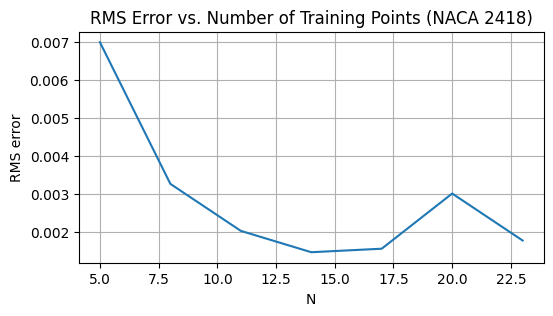

In [102]:
plt.figure(figsize=(6, 3))
plt.plot(N, RMS)
plt.grid(True)
plt.xlabel("N")
plt.ylabel("RMS error")
plt.title(f"RMS Error vs. Number of Training Points ({airfoil.name})")
plt.show()

## **6: Cubic SPLINE Interpolation**




> [**CODE REF**](https://chatgpt.com/c/6aa6aa70-5d8c-83e8-8f2e-434c3decba7b)





In [103]:
def cubic_spline(x, y, x_target):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_target = np.asarray(x_target, dtype=float)

    n = len(x)

    # Interval widths
    h = np.diff(x)

    # Construct the system for the second derivatives
    A = np.zeros((n - 2, n - 2))
    b = np.zeros(n - 2)

    for i in range(1, n - 1):
        row = i - 1

        A[row, row] = 2 * (h[i - 1] + h[i])

        if i > 1:
            A[row, row - 1] = h[i - 1]

        if i < n - 2:
            A[row, row + 1] = h[i]

        b[row] = 6 * (
            (y[i + 1] - y[i]) / h[i]
            - (y[i] - y[i - 1]) / h[i - 1]
        )

    # Natural boundary conditions:
    # M[0] = M[n-1] = 0
    M = np.zeros(n)
    M[1:n - 1] = np.linalg.solve(A, b)

    # Find the interval for every x_target
    i = np.searchsorted(x, x_target, side="right") - 1

    # If x_target == x[-1], use the last interval
    i = np.minimum(i, n - 2)

    # Distance from interval endpoints
    h_i = h[i]
    x_left = x[i]
    x_right = x[i + 1]

    # Cubic spline interpolation formula
    result = (
        M[i] * (x_right - x_target) ** 3 / (6 * h_i)
        + M[i + 1] * (x_target - x_left) ** 3 / (6 * h_i)
        + (y[i] / h_i - M[i] * h_i / 6)
          * (x_right - x_target)
        + (y[i + 1] / h_i - M[i + 1] * h_i / 6)
          * (x_target - x_left)
    )

    return result

In [104]:
x = [1, 2, 5, 11]
y = [4, 6, 25, 20]

y_u_interp_CSP = cubic_spline(x_u_train, y_u_train, x_u)
y_l_interp_CSP = cubic_spline(x_l_train, y_l_train, x_l)

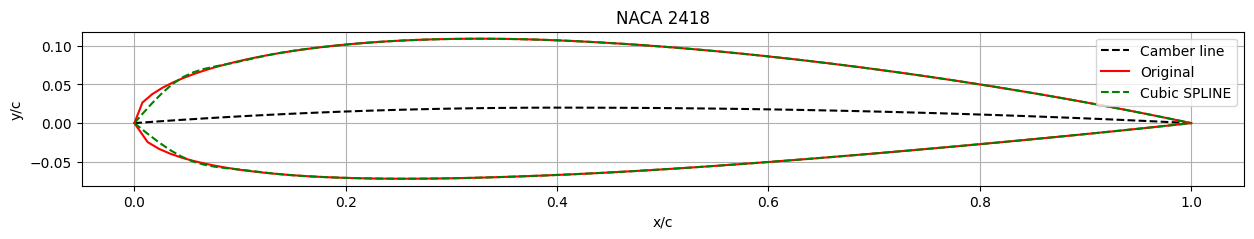

In [105]:
plt.figure(figsize=(15, 2))

plt.plot(eval_inp, y_c, "k--", label="Camber line")

plt.plot(x_u, y_u, "r", label="Original")
plt.plot(x_u, y_u_interp_CSP, "g--", label="Cubic SPLINE")

plt.plot(x_l, y_l, "r")
plt.plot(x_l, y_l_interp_CSP, "g--")

plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(airfoil.name)
plt.legend()
plt.show()

### **Error Determination**


##### **1: MAX Error**

In [106]:
# calculate MAX error
err_u = np.max(np.abs(y_u - y_u_interp_CSP))
err_l = np.max(np.abs(y_l - y_l_interp_CSP))
print(f"MAX error in upper surface: {err_u}")
print(f"MAX error in lower surface: {err_l}")

MAX error in upper surface: 0.014663790084976293
MAX error in lower surface: 0.010742140211231951


##### **2: RMS Error**

In [107]:
# calculate RMS error
adj = np.concatenate((y_u - y_u_interp_CSP, y_l - y_l_interp_CSP))
rms_error = np.sqrt(np.mean(adj**2))
print(f"RMS error: {rms_error}")

RMS error: 0.0017616380782736491


## **Result and Discussion**


*   **Lagrange Interpolation:**

    *   MAX error in upper surface: 0.0116
    *   MAX error in lower surface: 0.0094
    *   RMS error: 0.0014




*   **Cubic SPLINE Interpolation:**

    *   MAX error in upper surface: 0.0146
    *   MAX error in lower surface: 0.0107
    *   RMS error: 0.0018

*   **Increasing the number of points near leading edge can improve the the error**.

## **Conclusion**
*   Both the interpolation Technique correctly approximate the Airfoil curve along most of the airfoil surface with negligible error. But Leading edge has more cuvature as compare to Trailing Edge ,therefore both the Interpolation technique poorly approximate the curve near Leading edge.
